# Orchard surveys — rendement, fructification et anomalies temporelles
**G05 — contribution Merieme.** Analyse autonome du fichier nettoyé ; une ligne = un relevé mensuel d'un verger.
Le rendement étudié est `durian_yield_kg / orchard_area_ha` en **kg/ha par relevé mensuel**, pas un rendement annuel.

**Méthodes du groupe réutilisées :** EDA, corrélations Pearson/Spearman, IQR, Z-score, Z modifié, anomalies contextuelles par site, Isolation Forest et LOF. Contrairement à une analyse globale, on retire une référence saisonnière propre au site. Les valeurs signalées sont conservées.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import binom, fisher_exact
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
import sklearn, scipy, sys

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/data_dictionary.csv').exists()), None)
assert ROOT is not None, "Lancer le notebook depuis le dépôt."
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': .2,
                     'font.size': 10, 'figure.dpi': 100})
pd.set_option('display.max_columns', 18)
pd.set_option('display.max_rows', 25)
print('Versions :', sys.version.split()[0], 'pandas', pd.__version__,
      'numpy', np.__version__, 'scikit-learn', sklearn.__version__, 'scipy', scipy.__version__)

def lecture(nom, domaine, cle):
    raw = pd.read_csv(ROOT / 'data' / domaine / (nom + '.csv'))
    path = ROOT / 'data' / domaine / 'cleaned' / (nom + '_cleaned.csv')
    clean = pd.read_csv(path)
    display(pd.DataFrame({'source': ['brut', 'nettoyé'],
                          'lignes': [len(raw), len(clean)],
                          'colonnes': [raw.shape[1], clean.shape[1]],
                          'doublons_exacts': [raw.duplicated().sum(), clean.duplicated().sum()],
                          'doublons_cle': [raw.duplicated(cle).sum(), clean.duplicated(cle).sum()]}))
    display(pd.DataFrame({'type': clean.dtypes.astype(str), 'manquants': clean.isna().sum()}))
    assert clean[cle].notna().all() and clean[cle].is_unique, "Clé primaire à vérifier."
    return raw, clean

def statistiques(data, cle, variables, groupes=(), min_n=8, haut_seul=False):
    """Comparaisons rétrospectives au sein de groupes homogènes ; aucune imputation."""
    records = []
    grouped = data.groupby(list(groupes), dropna=False, sort=True) if groupes else [('ensemble', data)]
    for key, group in grouped:
        if groupes:
            keys = key if isinstance(key, tuple) else (key,)
            label = '; '.join(f'{c}={v}' for c, v in zip(groupes, keys))
        else:
            label = 'ensemble'
        for variable in variables:
            x = pd.to_numeric(group[variable], errors='raise').replace([np.inf, -np.inf], np.nan)
            good = x.dropna()
            n = len(good)
            q1, q3 = good.quantile([.25, .75]) if n else (np.nan, np.nan)
            iqr, mean, sd = q3 - q1, good.mean(), good.std(ddof=1)
            med = good.median()
            mad = (good - med).abs().median()
            specs = [
                ('IQR', q1-1.5*iqr, q3+1.5*iqr, x, iqr, 'hors Q1−1.5×IQR ; Q3+1.5×IQR'),
                ('Z-score', mean-3*sd, mean+3*sd, (x-mean)/sd if sd > 0 else x*0+np.nan, sd, '|z| > 3'),
                ('Z-modifie', med-3.5*mad/.6745, med+3.5*mad/.6745,
                 .6745*(x-med)/mad if mad > 0 else x*0+np.nan, mad, '|z_mod| > 3.5'),
            ]
            for method, lo, hi, scores, spread, rule in specs:
                usable = n >= min_n and pd.notna(spread) and spread > 1e-12
                if haut_seul: lo = -np.inf; rule += ' (queue haute uniquement)'
                for idx in group.index:
                    available = bool(usable and pd.notna(x.loc[idx]))
                    flag = bool(available and (x.loc[idx] < lo or x.loc[idx] > hi))
                    records.append({
                        'observation': str(group.at[idx, cle]), 'groupe': label,
                        'variable': variable, 'methode': method, 'valeur': x.loc[idx],
                        'score': scores.loc[idx] if available else np.nan,
                        'borne_basse': lo if usable else np.nan, 'borne_haute': hi if usable else np.nan,
                        'n_reference': n, 'applicable': available, 'signalee': flag,
                        'regle': rule if usable else f'Non évalué : n < {min_n} ou dispersion nulle',
                        'interpretation': 'Valeur atypique dans ce groupe ; contrôle du contexte nécessaire, pas une erreur établie.'
                    })
    return pd.DataFrame(records)

def resume_tests(tests):
    display(tests.groupby(['variable', 'methode']).agg(
        evaluations=('applicable', 'sum'), signalees=('signalee', 'sum')).reset_index())
    skipped = tests.loc[~tests.applicable, ['groupe','variable','methode','regle']].drop_duplicates()
    if len(skipped):
        print('Cas non évalués (extrait) :'); display(skipped.head(12))

def bh(pvalues):
    """Benjamini–Hochberg : ajustement descriptif des comparaisons multiples."""
    pvalues = np.asarray(pvalues, dtype=float)
    result = np.full(len(pvalues), np.nan)
    good = np.flatnonzero(np.isfinite(pvalues))
    if len(good):
        order = good[np.argsort(pvalues[good])]
        adjusted = pvalues[order] * len(good) / np.arange(1, len(good)+1)
        result[order] = np.minimum.accumulate(adjusted[::-1])[::-1].clip(0,1)
    return result

def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    rate = k/n; den = 1+z*z/n
    center = (rate+z*z/(2*n))/den
    half = z*np.sqrt(rate*(1-rate)/n+z*z/(4*n*n))/den
    # Les bornes exactes k=0/k=n évitent les erreurs d'arrondi à 1e-17.
    low = np.where(k == 0, 0., np.clip(center-half, 0, 1))
    high = np.where(k == n, 1., np.clip(center+half, 0, 1))
    return low, high

def frequences(data, facility, date):
    """Panel entre premier et dernier mois observés, y compris les zéros enregistrés."""
    frames = []
    for name, g in data.groupby(facility):
        periods = g[date].dt.to_period('M')
        grid = pd.period_range(periods.min(), periods.max(), freq='M')
        counts = periods.value_counts().reindex(grid, fill_value=0).sort_index()
        out = pd.DataFrame({'etablissement':name, 'mois':grid.to_timestamp(), 'n':counts.values})
        # Bords exclus : premier/dernier mois d'activité observée potentiellement incomplets.
        out['interieur'] = (np.arange(len(out)) > 0) & (np.arange(len(out)) < len(out)-1)
        out['historique_12'] = out['n'].shift(1).rolling(12, min_periods=12).sum()
        past_complete = out['interieur'].shift(1).rolling(12, min_periods=12).sum().eq(12)
        out['eligible'] = out['interieur'] & past_complete
        out['p_pic'] = np.nan
        ix = out['eligible']
        # Sous un taux constant, conditionnellement au total, le mois testé représente 1/13 de l'exposition.
        total = (out.loc[ix,'historique_12']+out.loc[ix,'n']).astype(int)
        out.loc[ix,'p_pic'] = binom.sf(out.loc[ix,'n']-1, total, 1/13)
        out['observation'] = str(name)+'|'+out['mois'].dt.strftime('%Y-%m')
        frames.append(out)
    out = pd.concat(frames, ignore_index=True)
    out['q_pic'] = bh(out.p_pic)
    out['pic_BH'] = out.q_pic.lt(.05)
    return out

def test_pics(panel):
    result = pd.DataFrame({
        'observation': panel.observation, 'groupe':panel.etablissement,
        'variable':'nombre_mensuel', 'methode':'Binomial_conditionnel_BH',
        'valeur': panel.n, 'score':panel.q_pic,
        'historique_12':panel.historique_12, 'p_brut':panel.p_pic,
        'borne_basse':0., 'borne_haute':.05, 'n_reference':12,
        'applicable':panel.eligible, 'signalee':panel.pic_BH,
        'regle':'q_BH < 0.05 ; comparaison aux 12 mois précédents, bords exclus',
        'interpretation':"Pic exploratoire sous hypothèse de taux constant et couverture continue ; vérifier collecte et saisonnalité."
    })
    return result

def bilan(tests, nom, domaine):
    """Conserve toutes les détections avec leur méthode ; une ligne peut être signalée plusieurs fois."""
    tests = tests.copy()
    tests['echelle_seuil'] = np.where(tests.methode.isin(['Binomial_conditionnel_BH','Fisher_exact_BH','IF','LOF','LOF_k5']), 'score', 'valeur')
    flagged = tests.loc[tests.signalee].copy()
    output = ROOT / 'data' / domaine / 'syntheses'
    output.mkdir(parents=True, exist_ok=True)
    flagged.to_csv(output / (nom+'_anomalies.csv'), index=False)
    # Les bornes restent interprétables avec variable, méthode et effectif de référence.
    cols = ['groupe','variable','methode','borne_basse','borne_haute','n_reference','regle','echelle_seuil']
    tests[cols].drop_duplicates().to_csv(output / (nom+'_seuils.csv'), index=False)
    assert flagged.observation.notna().all()
    print(f'{len(flagged)} détections ; {flagged.observation.nunique()} identifiants distincts (unités d’analyse précisées dans le notebook).')
    display(flagged.head(20))
    return flagged


Versions : 3.9.6 pandas 2.3.3 numpy 2.0.2 scikit-learn 1.6.1 scipy 1.13.1


## 1. Audit et choix des variables
La superficie doit être strictement positive ; le taux est en pourcentage. Les huit proportions corrigées lors du nettoyage constituent une hypothèse héritée à conserver dans la traçabilité et à valider si une source originale devient disponible. Les notes vides ne prouvent pas l'absence de perturbation.

In [2]:
raw,df=lecture('orchard_surveys','ecology','orchard_survey_id')
df['survey_period']=pd.to_datetime(df.survey_period,errors='raise')
df=df.sort_values(['site_code','survey_period']).reset_index(drop=True)
numeric=['orchard_area_ha','durian_flower_density','fruit_set_rate_pct','durian_yield_kg',
         'other_pollinator_activity','fertilizer_use_index','irrigation_level']
for col in numeric:df[col]=pd.to_numeric(df[col],errors='raise')
invalid=(df.orchard_area_ha.le(0)|df.durian_yield_kg.lt(0)|
         ~df.fruit_set_rate_pct.between(0,100)|df[numeric].isna().any(axis=1))
display(df.loc[invalid])
assert not invalid.any(), "Corriger ou isoler les lignes invalides avant calcul."
assert not df.duplicated(['site_code','survey_period']).any()
df['yield_kg_ha']=df.durian_yield_kg/df.orchard_area_ha
df['month']=df.survey_period.dt.month
df['year']=df.survey_period.dt.year
coverage=df.groupby('site_code').agg(n=('survey_period','size'),debut=('survey_period','min'),fin=('survey_period','max'),
                                    superficies_distinctes=('orchard_area_ha','nunique'))
display(coverage)
# Les différences temporelles ne sont calculées que si le pas est vraiment mensuel.
ordinal=df.survey_period.dt.year*12+df.survey_period.dt.month
gap=ordinal.groupby(df.site_code).diff()
assert gap.dropna().eq(1).all(), "Mois manquants : adapter les différences et lag 12."
display(df[['yield_kg_ha','fruit_set_rate_pct']].describe())


,source,lignes,colonnes,doublons_exacts,doublons_cle
0,brut,1250,11,2,2
1,nettoyé,1248,11,0,0


,type,manquants
orchard_survey_id,object,0
site_code,object,0
survey_period,object,0
orchard_area_ha,float64,0
durian_flower_density,float64,0
fruit_set_rate_pct,float64,0
durian_yield_kg,float64,0
other_pollinator_activity,float64,0
fertilizer_use_index,float64,0
irrigation_level,float64,0


,orchard_survey_id,site_code,survey_period,orchard_area_ha,durian_flower_density,fruit_set_rate_pct,durian_yield_kg,other_pollinator_activity,fertilizer_use_index,irrigation_level,agricultural_disturbance_note


,n,debut,fin,superficies_distinctes
site_code,,,,
AVL-ECJ,78,2019-01-01,2025-06-01,1
AVL-FNQ,78,2019-01-01,2025-06-01,1
AVL-GRB,78,2019-01-01,2025-06-01,1
AVL-HUA,78,2019-01-01,2025-06-01,1
AVL-KAR,78,2019-01-01,2025-06-01,1
AVL-MAR,78,2019-01-01,2025-06-01,1
AVL-NFR,78,2019-01-01,2025-06-01,1
AVL-NMQ,78,2019-01-01,2025-06-01,1
AVL-ORR,78,2019-01-01,2025-06-01,1


,yield_kg_ha,fruit_set_rate_pct
count,1248.000000,1248.000000
mean,1041.185472,53.550080
std,197.394017,9.307769
min,392.783088,27.300000
25%,905.848398,47.000000
50%,1038.250542,53.000000
75%,1164.736389,59.400000
max,1815.731518,87.700000


## 2. Comparaisons entre sites et saisonnalité
Les boîtes représentent des distributions de relevés mensuels. Le rendement par hectare neutralise la taille des vergers, mais pas leurs différences agronomiques. L'année 2025 s'arrête en juin : aucune comparaison de totaux annuels incomplets.

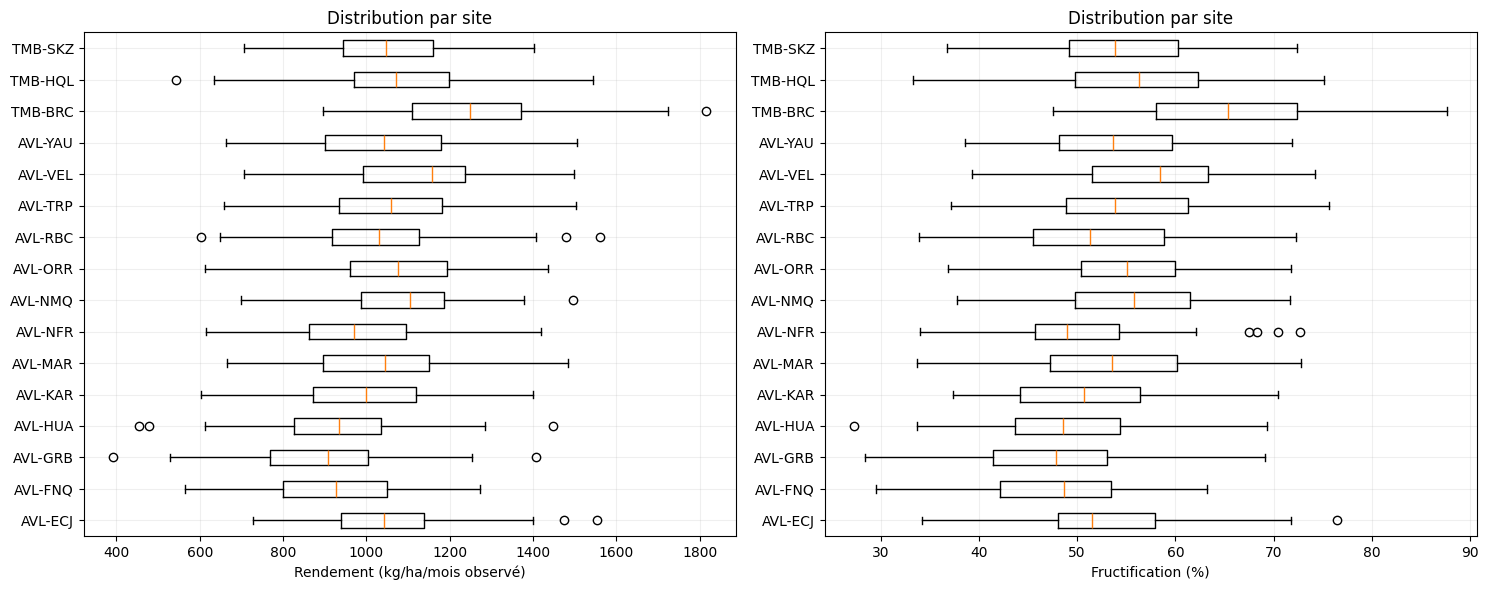

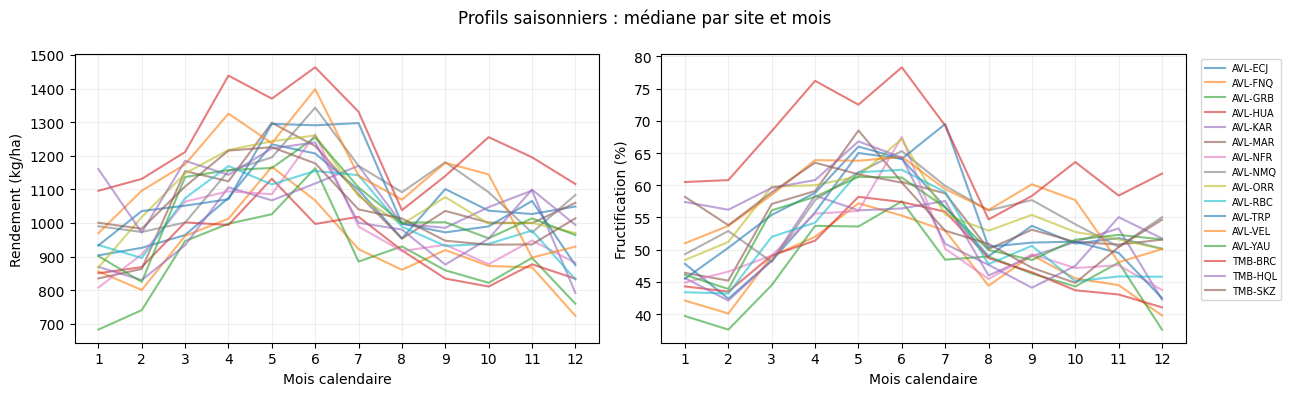

**Lecture :** les différences entre sites et entre mois motivent une référence locale saisonnière. Les variations brutes ne suffisent pas à conclure à une rupture.

In [3]:
sites=sorted(df.site_code.unique())
fig,axes=plt.subplots(1,2,figsize=(15,6))
for ax,var,label in zip(axes,['yield_kg_ha','fruit_set_rate_pct'],['Rendement (kg/ha/mois observé)','Fructification (%)']):
    ax.boxplot([df.loc[df.site_code.eq(s),var] for s in sites], vert=False, tick_labels=sites)
    ax.set_xlabel(label);ax.set_title('Distribution par site')
fig.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(13,4))
for site,g in df.groupby('site_code'):
    for ax,var in zip(axes,['yield_kg_ha','fruit_set_rate_pct']):
        med=g.groupby('month')[var].median()
        ax.plot(med.index,med.values,alpha=.6,label=site)
for ax,label in zip(axes,['Rendement (kg/ha)','Fructification (%)']):
    ax.set_xlabel('Mois calendaire');ax.set_ylabel(label);ax.set_xticks(range(1,13))
axes[1].legend(bbox_to_anchor=(1.02,1),fontsize=7)
fig.suptitle('Profils saisonniers : médiane par site et mois');fig.tight_layout();plt.show()
display(Markdown("**Lecture :** les différences entre sites et entre mois motivent une référence locale saisonnière. Les variations brutes ne suffisent pas à conclure à une rupture."))


### Comparaison interannuelle à période constante
On compare les moyennes mensuelles de janvier à juin pour toutes les années, afin de ne pas confondre une année 2025 incomplète avec une baisse annuelle. Les différences restent descriptives, sans test causal.


In [4]:
first_half=df.loc[df.month.le(6)].groupby(['site_code','year']).agg(yield_mean=('yield_kg_ha','mean'),fruit_mean=('fruit_set_rate_pct','mean'),n=('orchard_survey_id','size'))
assert first_half.n.eq(6).all(), 'Semestres incomplets : ne pas comparer directement.'
display(first_half.yield_mean.unstack().round(1))
display(first_half.fruit_mean.unstack().round(1))
recent=first_half.xs(2025,level='year').join(first_half.xs(2024,level='year'),lsuffix='_2025',rsuffix='_2024')
recent['yield_change_pct']=(recent.yield_mean_2025/recent.yield_mean_2024-1)*100
recent['fruit_change_pp']=recent.fruit_mean_2025-recent.fruit_mean_2024
display(recent[['yield_change_pct','fruit_change_pp']].sort_values('yield_change_pct').round(2))
display(Markdown('**Lecture :** les tableaux distinguent un niveau propre au site, une variation d’une année à l’autre et un incident mensuel. Une baisse ponctuelle ne démontre pas un déclin durable.'))


year,2019,2020,2021,2022,2023,2024,2025
site_code,,,,,,,
AVL-ECJ,1114.8,1025.0,1041.1,1011.0,1047.0,1178.7,1059.6
AVL-FNQ,1045.4,1014.6,856.5,890.1,1010.2,980.1,983.6
AVL-GRB,891.1,898.7,954.6,960.4,914.4,903.6,952.9
AVL-HUA,950.6,1003.1,1030.3,898.6,991.5,935.8,966.9
AVL-KAR,1011.9,1062.1,1012.8,999.2,988.9,1005.5,976.8
AVL-MAR,1026.0,1060.7,1025.7,1023.4,1063.4,1111.3,1128.4
AVL-NFR,1039.8,905.2,1020.3,965.1,1000.6,1165.9,1043.7
AVL-NMQ,1128.2,1022.9,1035.6,1173.4,1149.7,1096.0,1107.2
AVL-ORR,1055.9,1141.8,1140.6,1188.5,1168.0,1087.5,1077.4


year,2019,2020,2021,2022,2023,2024,2025
site_code,,,,,,,
AVL-ECJ,57.2,53.0,52.1,52.3,53.1,58.2,54.4
AVL-FNQ,52.7,51.1,45.6,49.7,51.1,49.0,50.0
AVL-GRB,46.4,46.7,49.6,51.4,44.4,47.9,49.2
AVL-HUA,50.6,51.1,52.4,48.1,50.7,49.8,50.2
AVL-KAR,51.8,53.4,51.5,51.5,50.1,52.1,48.7
AVL-MAR,50.7,55.5,54.9,54.6,55.8,57.8,56.8
AVL-NFR,51.0,48.8,54.4,52.8,50.6,56.2,53.6
AVL-NMQ,58.4,54.4,53.7,59.8,57.8,55.9,54.4
AVL-ORR,54.3,57.6,56.2,60.0,59.0,53.8,57.5


,yield_change_pct,fruit_change_pp
site_code,,
AVL-NFR,-10.48,-2.58
AVL-ECJ,-10.10,-3.78
AVL-RBC,-5.56,-2.42
AVL-KAR,-2.86,-3.38
TMB-SKZ,-2.68,-3.53
AVL-ORR,-0.92,3.68
TMB-BRC,-0.39,0.23
TMB-HQL,0.22,0.77
AVL-FNQ,0.36,1.02


**Lecture :** les tableaux distinguent un niveau propre au site, une variation d’une année à l’autre et un incident mensuel. Une baisse ponctuelle ne démontre pas un déclin durable.

## 3. Référence saisonnière et variations
Pour chaque mesure : médiane du **même site et du même mois calendaire dans les autres années**, en excluant le relevé testé. Six à sept années disponibles rendent cette référence estimée, non certaine.
Résidu = mesure − référence. Les scores sont ensuite calculés sur les résidus du site (78 mois).
Les variations brutales portent sur la différence mensuelle de ces résidus, pour limiter l'effet saisonnier.
Le changement sur 12 mois est affiché en complément : rendement en %, fructification en **points de pourcentage**.
Analyse rétrospective : des années ultérieures participent à la référence ; ce n'est pas un modèle de prévision.

In [5]:
features=['yield_kg_ha','fruit_set_rate_pct','durian_flower_density',
          'other_pollinator_activity','fertilizer_use_index','irrigation_level']
for var in features:
    baseline=pd.Series(np.nan,index=df.index)
    for _,g in df.groupby(['site_code','month']):
        for idx in g.index:
            other=g.loc[g.index!=idx,var].dropna()
            if len(other)>=4:baseline.at[idx]=other.median()
    df[var+'_expected']=baseline
    df[var+'_resid']=df[var]-baseline
for var in ['yield_kg_ha','fruit_set_rate_pct']:
    df[var+'_delta_resid']=df.groupby('site_code')[var+'_resid'].diff()
prev_yield=df.groupby('site_code').yield_kg_ha.shift(12)
df['yield_yoy_pct']=(df.yield_kg_ha/prev_yield-1)*100
df['fruit_yoy_pp']=df.fruit_set_rate_pct-df.groupby('site_code').fruit_set_rate_pct.shift(12)
assert df[[v+'_resid' for v in features]].notna().all().all()
display(df.nsmallest(10,'yield_yoy_pct')[['orchard_survey_id','site_code','survey_period',
     'yield_kg_ha','yield_yoy_pct','fruit_yoy_pp','agricultural_disturbance_note']])


,orchard_survey_id,site_code,survey_period,yield_kg_ha,yield_yoy_pct,fruit_yoy_pp,agricultural_disturbance_note
265,ORC-0000812,AVL-HUA,2021-08-01,477.991614,-54.546234,-22.8,NaN
1136,ORC-0001215,TMB-HQL,2022-09-01,542.592760,-49.390344,-17.1,NaN
685,ORC-0000218,AVL-ORR,2024-02-01,611.862647,-46.131623,-17.2,NaN
1111,ORC-0001190,TMB-HQL,2020-08-01,633.255656,-45.856425,-29.1,NaN
271,ORC-0000818,AVL-HUA,2022-02-01,454.270440,-45.067712,-7.5,NaN
517,ORC-0000362,AVL-NFR,2023-02-01,613.905738,-43.542302,-16.3,NaN
826,ORC-0000281,AVL-TRP,2022-11-01,727.385740,-40.255119,-21.5,NaN
133,ORC-0000992,AVL-FNQ,2023-08-01,658.607330,-39.440593,-22.6,NaN
558,ORC-0000871,AVL-NMQ,2020-01-01,698.092652,-39.042095,-13.7,NaN
189,ORC-0000424,AVL-GRB,2021-10-01,705.025735,-38.326786,-21.8,NaN


### Règles de lecture communes
IQR : bornes Q1 − 1,5×IQR et Q3 + 1,5×IQR ; Z-score : |z| > 3 ; Z modifié : 0,6745×(x−médiane)/MAD, seuil 3,5.
Ces seuils exploratoires viennent des notebooks du groupe, pas d'une vérité terrain.
Les groupes de moins de 8 observations et les dispersions nulles sont déclarés **non évaluables** : pas de division par zéro, ni de classement automatique de toute valeur non nulle comme anomalie.
Les comparaisons utilisent des groupes explicites ; elles sont rétrospectives et n'estiment pas une causalité.
Les résultats complets signalés et les seuils sont exportés uniquement dans `syntheses/`. Les fichiers bruts et nettoyés ne sont pas modifiés.


In [6]:
variables=['yield_kg_ha_resid','fruit_set_rate_pct_resid',
           'yield_kg_ha_delta_resid','fruit_set_rate_pct_delta_resid']
tests=statistiques(df,'orchard_survey_id',variables,['site_code'])
resume_tests(tests)
df['stat_flag']=df.orchard_survey_id.isin(tests.loc[tests.signalee,'observation'])
stats_summary=df.groupby('site_code').agg(releves=('orchard_survey_id','size'),signales=('stat_flag','sum'))
display(stats_summary)
display(Markdown(f"**Lecture calculée :** {int(df.stat_flag.sum())} relevés présentent au moins un signal parmi "
                "les trois méthodes et les quatre variables contextuelles. Les tests sont corrélés : le nombre de détections n'est pas un nombre de preuves indépendantes."))


,variable,methode,evaluations,signalees
0,fruit_set_rate_pct_delta_resid,IQR,1232,5
1,fruit_set_rate_pct_delta_resid,Z-modifie,1232,0
2,fruit_set_rate_pct_delta_resid,Z-score,1232,0
3,fruit_set_rate_pct_resid,IQR,1248,9
4,fruit_set_rate_pct_resid,Z-modifie,1248,0
5,fruit_set_rate_pct_resid,Z-score,1248,1
6,yield_kg_ha_delta_resid,IQR,1232,18
7,yield_kg_ha_delta_resid,Z-modifie,1232,6
8,yield_kg_ha_delta_resid,Z-score,1232,2
9,yield_kg_ha_resid,IQR,1248,14


Cas non évalués (extrait) :


,groupe,variable,methode,regle
468,site_code=AVL-ECJ,yield_kg_ha_delta_resid,IQR,hors Q1−1.5×IQR ; Q3+1.5×IQR
546,site_code=AVL-ECJ,yield_kg_ha_delta_resid,Z-score,|z| > 3
624,site_code=AVL-ECJ,yield_kg_ha_delta_resid,Z-modifie,|z_mod| > 3.5
702,site_code=AVL-ECJ,fruit_set_rate_pct_delta_resid,IQR,hors Q1−1.5×IQR ; Q3+1.5×IQR
780,site_code=AVL-ECJ,fruit_set_rate_pct_delta_resid,Z-score,|z| > 3
858,site_code=AVL-ECJ,fruit_set_rate_pct_delta_resid,Z-modifie,|z_mod| > 3.5
1404,site_code=AVL-FNQ,yield_kg_ha_delta_resid,IQR,hors Q1−1.5×IQR ; Q3+1.5×IQR
1482,site_code=AVL-FNQ,yield_kg_ha_delta_resid,Z-score,|z| > 3
1560,site_code=AVL-FNQ,yield_kg_ha_delta_resid,Z-modifie,|z_mod| > 3.5
1638,site_code=AVL-FNQ,fruit_set_rate_pct_delta_resid,IQR,hors Q1−1.5×IQR ; Q3+1.5×IQR


,releves,signales
site_code,,
AVL-ECJ,78,4
AVL-FNQ,78,3
AVL-GRB,78,1
AVL-HUA,78,7
AVL-KAR,78,0
AVL-MAR,78,1
AVL-NFR,78,5
AVL-NMQ,78,0
AVL-ORR,78,0


**Lecture calculée :** 35 relevés présentent au moins un signal parmi les trois méthodes et les quatre variables contextuelles. Les tests sont corrélés : le nombre de détections n'est pas un nombre de preuves indépendantes.

## 4. Évolutions individuelles et localisation des signaux
Chaque panneau a son propre axe vertical pour voir les changements locaux ; ne pas comparer visuellement les amplitudes entre panneaux sans lire l'échelle. Les points rouges concernent uniquement la mesure représentée.

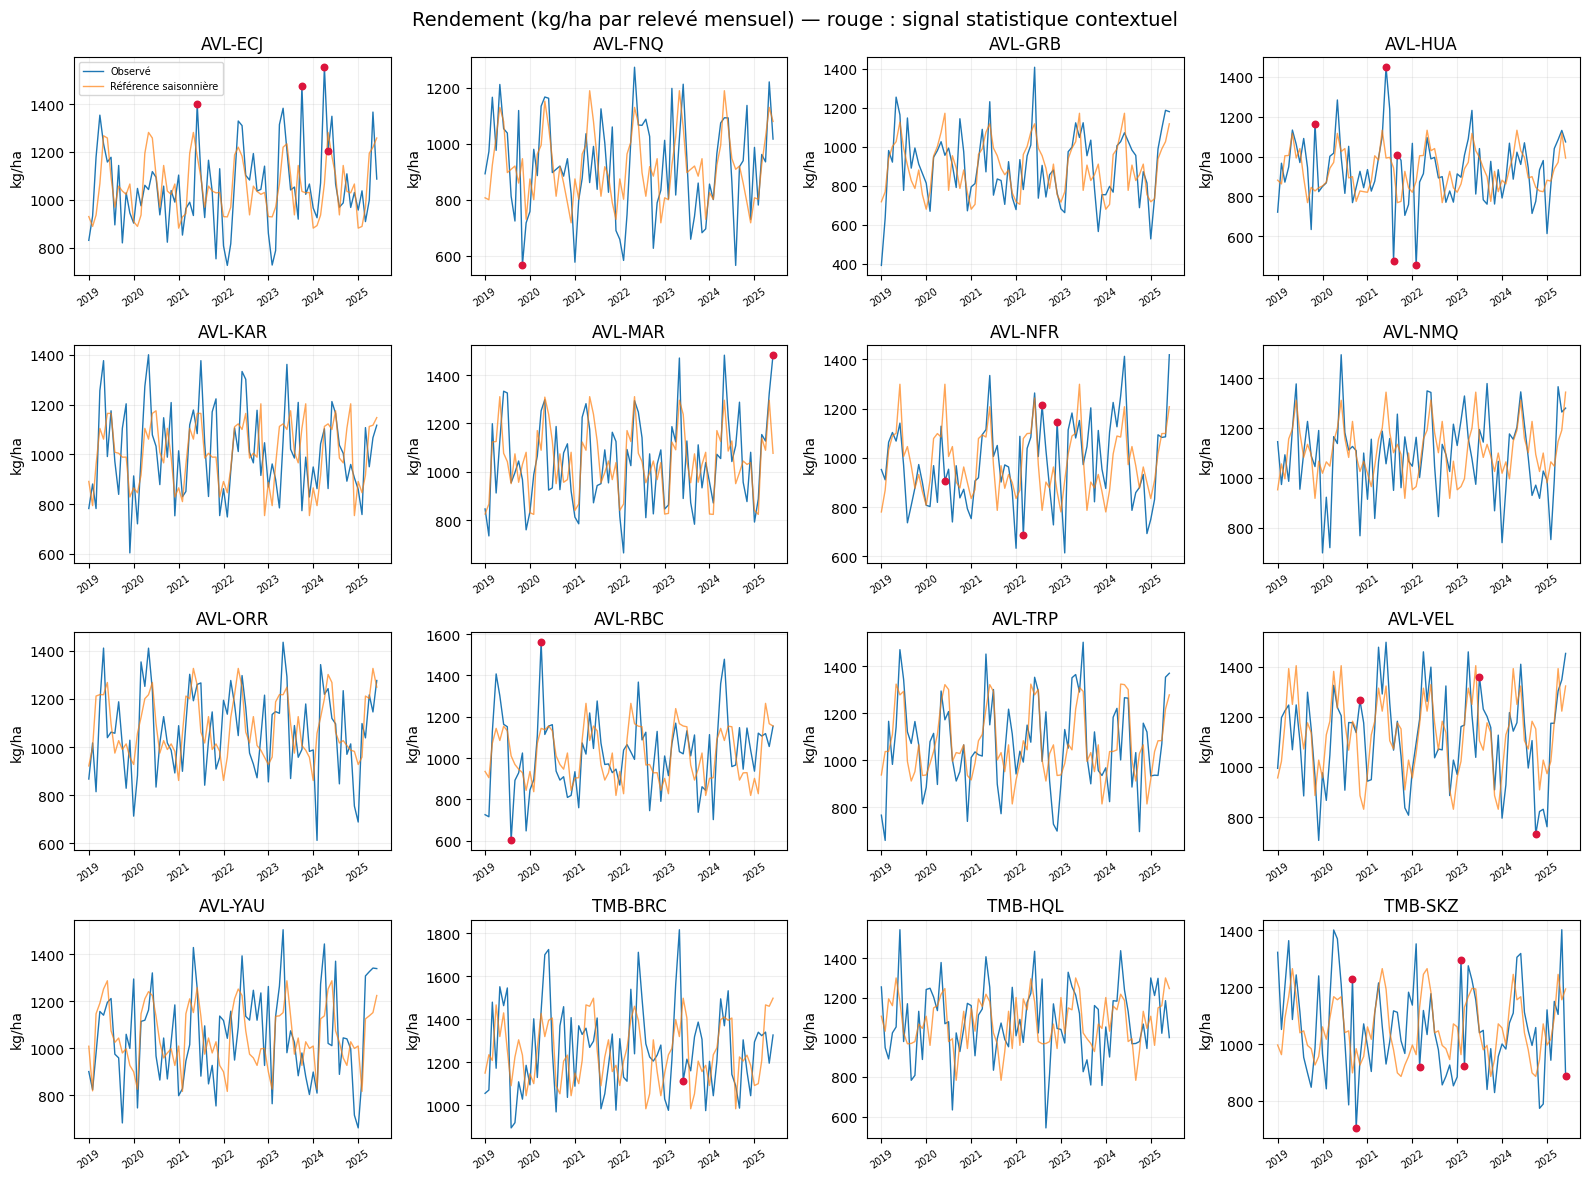

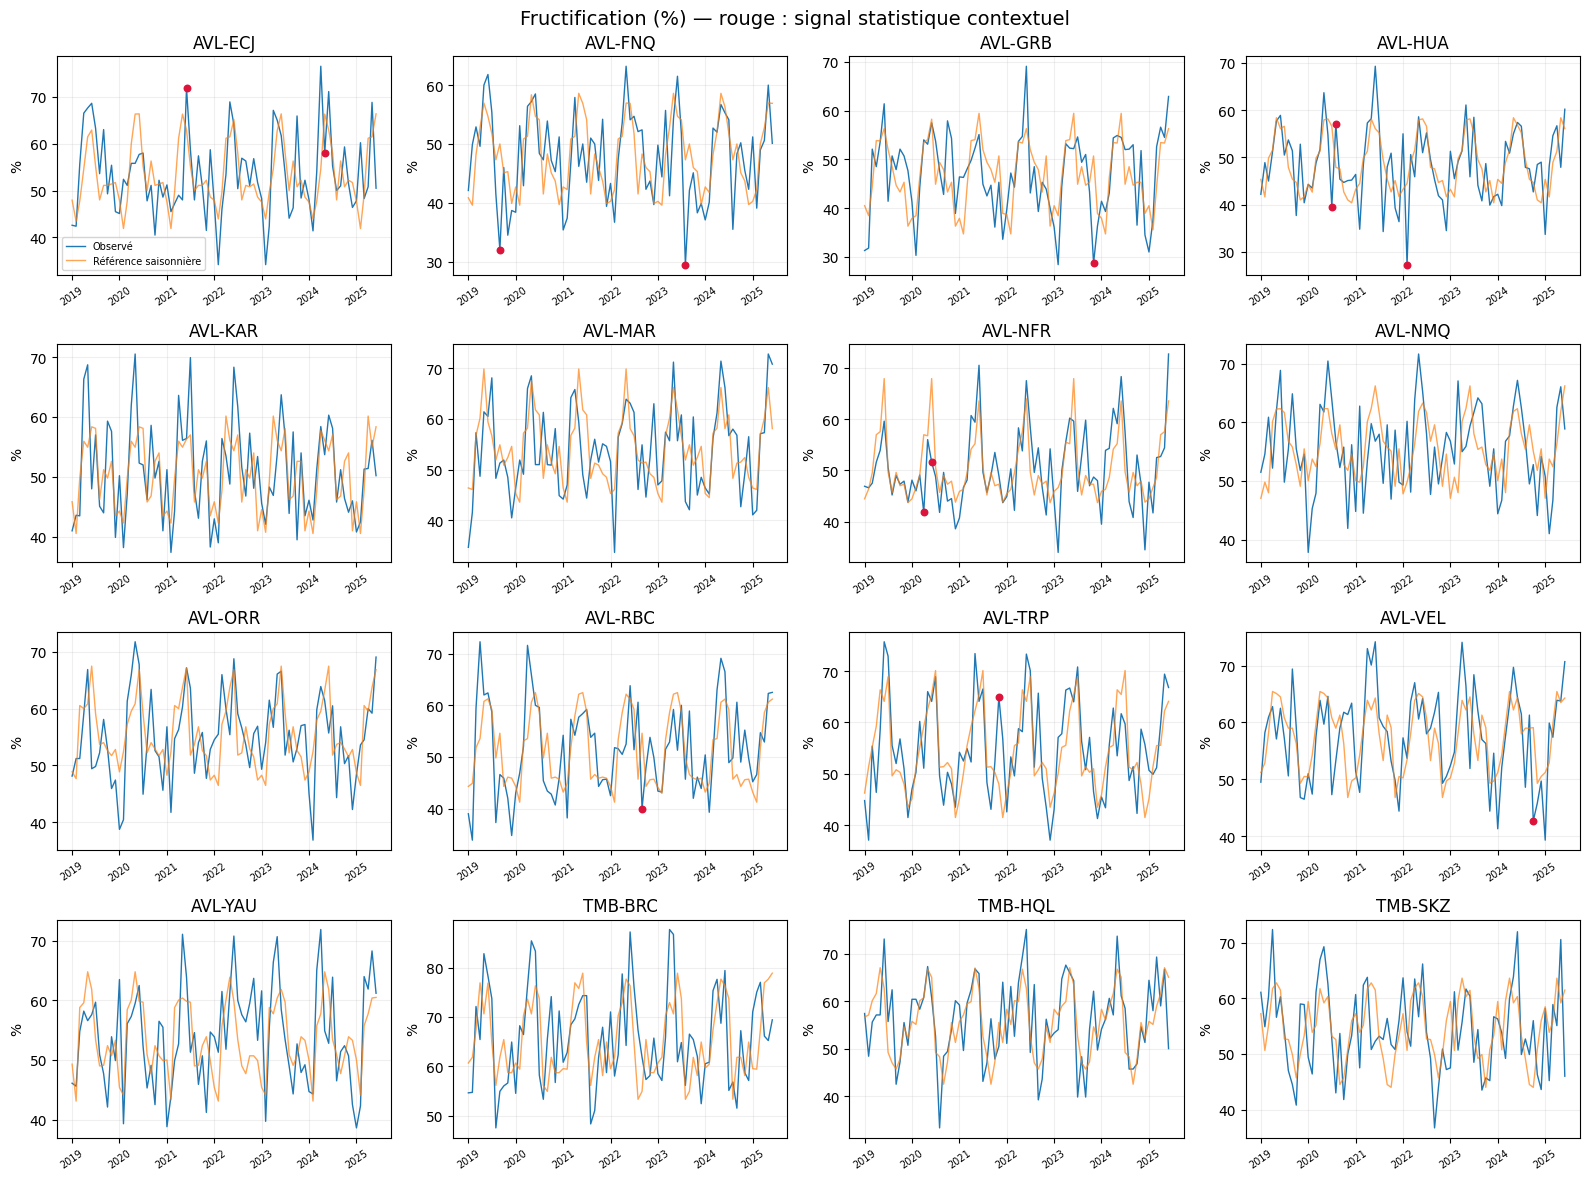

In [7]:
for var,label in [('yield_kg_ha','Rendement (kg/ha par relevé mensuel)'),
                  ('fruit_set_rate_pct','Fructification (%)')]:
    marked=tests.loc[tests.signalee & tests.variable.str.startswith(var),'observation']
    fig,axes=plt.subplots(4,4,figsize=(16,12))
    for ax,site in zip(axes.flat,sites):
        g=df.loc[df.site_code.eq(site)]
        ax.plot(g.survey_period,g[var],lw=1,label='Observé')
        ax.plot(g.survey_period,g[var+'_expected'],lw=1,alpha=.7,label='Référence saisonnière')
        high=g.orchard_survey_id.isin(marked)
        ax.scatter(g.loc[high,'survey_period'],g.loc[high,var],s=22,c='crimson',zorder=3)
        ax.set_title(site);ax.tick_params(axis='x',rotation=35,labelsize=7)
        ax.set_ylabel('kg/ha' if var=='yield_kg_ha' else '%')
    axes.flat[0].legend(fontsize=7)
    fig.suptitle(label+' — rouge : signal statistique contextuel',fontsize=14)
    fig.tight_layout();plt.show()


## 5. Profils multivariés : Isolation Forest et LOF
Six résidus saisonniers sont centrés-réduits **au sein du site**, puis standardisés pour la matrice commune. Aucun identifiant, date ou note n'entre dans les modèles.
Paramètres principaux repris d'`environmental_monthly` : IF 200 arbres, seed 42, contamination 2 % ; LOF 20 voisins, contamination 2 %.
Un quota de 2 % sélectionne des profils rares même si les données sont parfaitement valides. Le consensus est un accord entre méthodes, pas une confirmation. Les relations entre rendement et fructification peuvent compter partiellement deux fois le même phénomène.

stat_flag    35
IF_flag      25
LOF_flag     25
consensus    12
Name: releves, dtype: int64

,orchard_survey_id,site_code,survey_period,yield_kg_ha,fruit_set_rate_pct,IF_score,LOF_score,agricultural_disturbance_note
15,ORC-0000484,AVL-ECJ,2020-04-01,1061.090312,55.8,0.558631,1.426026,NaN
57,ORC-0000526,AVL-ECJ,2023-10-01,1474.579639,65.9,0.578419,1.589948,NaN
63,ORC-0000532,AVL-ECJ,2024-04-01,1553.546798,76.5,0.608671,1.592816,NaN
145,ORC-0001004,AVL-FNQ,2024-08-01,565.086387,35.5,0.573674,1.608919,NaN
182,ORC-0000417,AVL-GRB,2021-03-01,930.516544,48.0,0.574046,1.458447,NaN
197,ORC-0000432,AVL-GRB,2022-06-01,1406.674632,69.1,0.565279,1.463682,NaN
263,ORC-0000810,AVL-HUA,2021-06-01,1448.167715,69.3,0.611806,1.395007,NaN
437,ORC-0000048,AVL-MAR,2022-12-01,1090.846473,63.0,0.601432,1.575532,NaN
637,ORC-0000170,AVL-ORR,2020-02-01,882.023451,40.4,0.557087,1.583744,NaN
717,ORC-0000562,AVL-RBC,2020-04-01,1560.758446,71.6,0.650885,1.690844,NaN


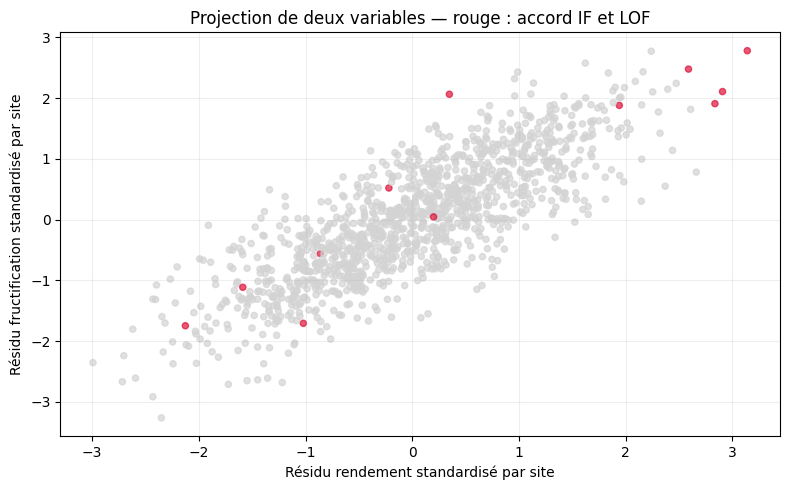

In [8]:
residual_cols=[v+'_resid' for v in features]
X=df[residual_cols].copy()
for col in residual_cols:
    local_mean=df.groupby('site_code')[col].transform('mean')
    local_sd=df.groupby('site_code')[col].transform('std')
    assert local_sd.gt(0).all()
    X[col]=(df[col]-local_mean)/local_sd
Xs=StandardScaler().fit_transform(X)
iso=IsolationForest(n_estimators=200,contamination=.02,random_state=42,n_jobs=1).fit(Xs)
lof=LocalOutlierFactor(n_neighbors=20,contamination=.02)
df['IF_flag']=iso.predict(Xs)==-1;df['IF_score']=-iso.score_samples(Xs)
df['LOF_flag']=lof.fit_predict(Xs)==-1;df['LOF_score']=-lof.negative_outlier_factor_
df['consensus']=df.IF_flag & df.LOF_flag
display(df[['stat_flag','IF_flag','LOF_flag','consensus']].sum().rename('releves'))
display(df.loc[df.consensus, ['orchard_survey_id','site_code','survey_period','yield_kg_ha',
       'fruit_set_rate_pct','IF_score','LOF_score','agricultural_disturbance_note']])
fig,ax=plt.subplots(figsize=(8,5))
ax.scatter(X.iloc[:,0],X.iloc[:,1],c=np.where(df.consensus,'crimson','lightgrey'),s=20,alpha=.7)
ax.set_xlabel('Résidu rendement standardisé par site');ax.set_ylabel('Résidu fructification standardisé par site')
ax.set_title('Projection de deux variables — rouge : accord IF et LOF')
fig.tight_layout();plt.show()


,contamination,voisins_LOF,IF,LOF,accord
0,0.01,10,13,13,5
1,0.01,20,13,13,5
2,0.01,35,13,13,7
3,0.02,10,25,25,11
4,0.02,20,25,25,12
5,0.02,35,25,25,14
6,0.05,10,63,63,27
7,0.05,20,63,63,30
8,0.05,35,63,63,34


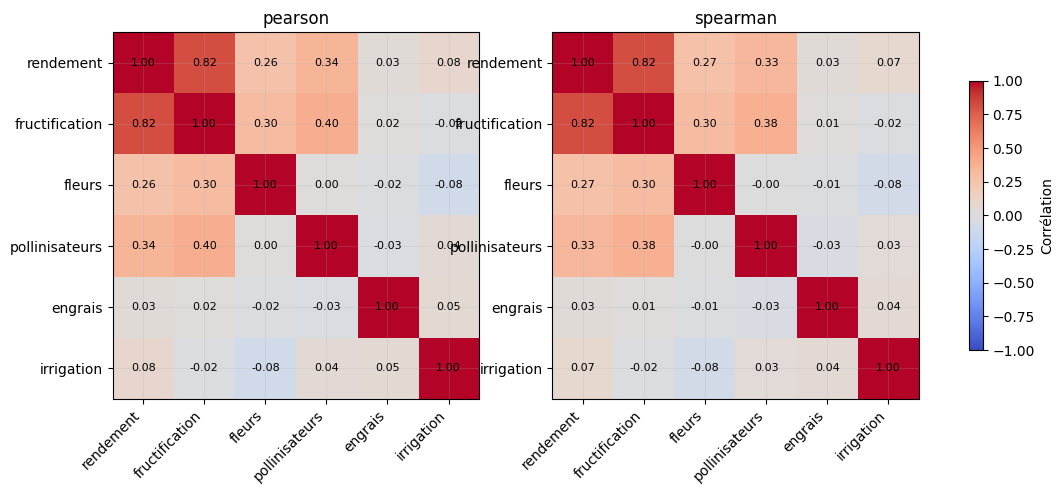

**Lecture :** si les listes changent avec le voisinage ou le quota, les profils sont sensibles au paramétrage. Ces scores servent à prioriser une lecture des séries, pas à supprimer des relevés.

In [9]:
sensitivity=[]
for contamination in [.01,.02,.05]:
    if_cut=np.quantile(df.IF_score,1-contamination)
    for k in [10,20,35]:
        model=LocalOutlierFactor(n_neighbors=k,contamination=contamination)
        flags=model.fit_predict(Xs)==-1
        sensitivity.append({'contamination':contamination,'voisins_LOF':k,
            'IF':int(df.IF_score.gt(if_cut).sum()),'LOF':int(flags.sum()),
            'accord':int((df.IF_score.gt(if_cut)&flags).sum())})
display(pd.DataFrame(sensitivity))
# Corrélation sur les résidus : les relations restent descriptives.
fig,axes=plt.subplots(1,2,figsize=(13,5))
short=['rendement','fructification','fleurs','pollinisateurs','engrais','irrigation']
for ax,method in zip(axes,['pearson','spearman']):
    mat=X.corr(method=method)
    im=ax.imshow(mat,vmin=-1,vmax=1,cmap='coolwarm')
    ax.set_xticks(range(len(short)),short,rotation=45,ha='right')
    ax.set_yticks(range(len(short)),short);ax.set_title(method)
    for i in range(len(short)):
        for j in range(len(short)):ax.text(j,i,f'{mat.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8)
fig.colorbar(im,ax=list(axes),shrink=.7,label='Corrélation')
plt.show()
display(Markdown("**Lecture :** si les listes changent avec le voisinage ou le quota, les profils sont sensibles au paramétrage. Ces scores servent à prioriser une lecture des séries, pas à supprimer des relevés."))


## 6. Registre, bilan et limites

In [10]:
ml=[]
for name,cut in [('IF',-iso.offset_),('LOF',-lof.offset_)]:
    ml.append(pd.DataFrame({
        'observation':df.orchard_survey_id,'groupe':df.site_code,
        'variable':'résidus : '+', '.join(features),'methode':name,
        'valeur':df[name+'_score'],'score':df[name+'_score'],'borne_basse':-np.inf,'borne_haute':cut,
        'n_reference':len(df),'applicable':True,'signalee':df[name+'_flag'],
        'regle':f'score > {cut:.6g} ; contamination=0.02',
        'interpretation':'Combinaison rare de mesures corrigées du site et de la saison ; vérifier série et notes.'
    }))
all_tests=pd.concat([tests,*ml],ignore_index=True)
meta=df[['orchard_survey_id','site_code','survey_period','yield_kg_ha','fruit_set_rate_pct',
         'yield_yoy_pct','fruit_yoy_pp','agricultural_disturbance_note']]
all_tests=all_tests.merge(meta,left_on='observation',right_on='orchard_survey_id',how='left',validate='many_to_one')
all_tests['interpretation']=all_tests.interpretation+' Note renseignée : '+all_tests.agricultural_disturbance_note.fillna('[aucune note renseignée, cause inconnue]')
register=bilan(all_tests,'orchard_surveys','ecology')
worst=df.nsmallest(1,'yield_yoy_pct').iloc[0]
summary={'n':len(df),'stats':int(df.stat_flag.sum()),'IF':int(df.IF_flag.sum()),'LOF':int(df.LOF_flag.sum()),
         'consensus':int(df.consensus.sum()),'max_yoy_drop_id':worst.orchard_survey_id,
         'max_yoy_drop_pct':float(worst.yield_yoy_pct),'max_yoy_drop_site':worst.site_code}
display(Markdown(f"**Bilan calculé :** {summary['stats']} relevés signalés par les tests contextuels ; "
                f"IF {summary['IF']}, LOF {summary['LOF']}, accord {summary['consensus']}. "
                f"La baisse annuelle relative la plus forte est {worst.yield_yoy_pct:.1f} % "
                f"pour {worst.orchard_survey_id} ({worst.site_code}, {worst.survey_period:%Y-%m}). "
                "Une baisse annuelle ne prouve ni erreur ni cause environnementale : les séries et les notes doivent être relues."))
assert df.orchard_survey_id.is_unique
assert len(df)==len(raw.drop_duplicates())


106 détections ; 64 identifiants distincts (unités d’analyse précisées dans le notebook).


,observation,groupe,variable,methode,valeur,score,borne_basse,borne_haute,n_reference,...,orchard_survey_id,site_code,survey_period,yield_kg_ha,fruit_set_rate_pct,yield_yoy_pct,fruit_yoy_pp,agricultural_disturbance_note,echelle_seuil
57,ORC-0000526,site_code=AVL-ECJ,yield_kg_ha_resid,IQR,438.926108,438.926108,-408.372024,414.311884,78,...,ORC-0000526,AVL-ECJ,2023-10-01,1474.579639,65.9,42.178901,14.8,NaN,valeur
63,ORC-0000532,site_code=AVL-ECJ,yield_kg_ha_resid,IQR,485.854680,485.854680,-408.372024,414.311884,78,...,ORC-0000532,AVL-ECJ,2024-04-01,1553.546798,76.5,18.179990,9.4,NaN,valeur
141,ORC-0000532,site_code=AVL-ECJ,yield_kg_ha_resid,Z-score,485.854680,3.141657,-463.922693,463.948166,78,...,ORC-0000532,AVL-ECJ,2024-04-01,1553.546798,76.5,18.179990,9.4,NaN,valeur
497,ORC-0000498,site_code=AVL-ECJ,yield_kg_ha_delta_resid,IQR,563.687192,563.687192,-545.155583,547.307471,77,...,ORC-0000498,AVL-ECJ,2021-06-01,1399.499179,71.8,25.153451,14.1,NaN,valeur
525,ORC-0000526,site_code=AVL-ECJ,yield_kg_ha_delta_resid,IQR,662.921182,662.921182,-545.155583,547.307471,77,...,ORC-0000526,AVL-ECJ,2023-10-01,1474.579639,65.9,42.178901,14.8,NaN,valeur
532,ORC-0000533,site_code=AVL-ECJ,yield_kg_ha_delta_resid,IQR,-561.379310,-561.379310,-545.155583,547.307471,77,...,ORC-0000533,AVL-ECJ,2024-05-01,1206.093596,57.9,-12.761459,-7.1,NaN,valeur
603,ORC-0000526,site_code=AVL-ECJ,yield_kg_ha_delta_resid,Z-score,662.921182,3.017797,-660.880001,659.006139,77,...,ORC-0000526,AVL-ECJ,2023-10-01,1474.579639,65.9,42.178901,14.8,NaN,valeur
731,ORC-0000498,site_code=AVL-ECJ,fruit_set_rate_pct_delta_resid,IQR,27.200000,27.200000,-26.700000,26.100000,77,...,ORC-0000498,AVL-ECJ,2021-06-01,1399.499179,71.8,25.153451,14.1,NaN,valeur
766,ORC-0000533,site_code=AVL-ECJ,fruit_set_rate_pct_delta_resid,IQR,-30.300000,-30.300000,-26.700000,26.100000,77,...,ORC-0000533,AVL-ECJ,2024-05-01,1206.093596,57.9,-12.761459,-7.1,NaN,valeur
946,ORC-0000947,site_code=AVL-FNQ,yield_kg_ha_resid,IQR,-378.994764,-378.994764,-378.603894,393.551865,78,...,ORC-0000947,AVL-FNQ,2019-11-01,567.500000,34.5,NaN,NaN,storm-related flower loss,valeur


**Bilan calculé :** 35 relevés signalés par les tests contextuels ; IF 25, LOF 25, accord 12. La baisse annuelle relative la plus forte est -54.5 % pour ORC-0000812 (AVL-HUA, 2021-08). Une baisse annuelle ne prouve ni erreur ni cause environnementale : les séries et les notes doivent être relues.

## 7. Vérification complémentaire M2 — rapprochement avec les relevés de chauves-souris

Les deux sources contiennent le même `site_code` et des observations datées. Nous construisons donc une table **site × mois** (sans associer arbitrairement deux lignes), puis cherchons une association descriptive entre rendement et observations de chauves-souris. Pour réduire la confusion par différences durables entre sites et cycles saisonniers, nous utilisons d'abord les **résidus saisonniers déjà calculés**. Un coefficient de Spearman ne démontre pas que les chauves-souris causent les changements de rendement : observation des chauves-souris, effort d'échantillonnage, climat et agriculture peuvent agir simultanément. Aucune imputation ni sélection sur la base des anomalies n'est effectuée.


In [11]:
from scipy.stats import spearmanr
bat_path=ROOT/'data/ecology/cleaned/bat_surveys_cleaned.csv'
bat=pd.read_csv(bat_path,usecols=['site_code','survey_start','observed_bat_count','observation_hours'])
bat['survey_start']=pd.to_datetime(bat.survey_start,errors='raise')
for col in ['observed_bat_count','observation_hours']:
    bat[col]=pd.to_numeric(bat[col],errors='coerce')
bat['month']=bat.survey_start.dt.to_period('M')
# Agrégation explicite et sans suppression en cas de plusieurs visites le même mois.
bat_month=bat.groupby(['site_code','month']).agg(
    observations=('survey_start','size'),bat_count=('observed_bat_count','sum'),
    hours=('observation_hours','sum')).reset_index()
bat_month['bats_per_hour']=bat_month.bat_count/bat_month.hours.replace(0,np.nan)
orchard_month=df[['orchard_survey_id','site_code','survey_period','yield_kg_ha_resid',
                  'fruit_set_rate_pct_resid','stat_flag']].copy()
orchard_month['month']=orchard_month.survey_period.dt.to_period('M')
assert not orchard_month.duplicated(['site_code','month']).any()
linked=orchard_month.merge(bat_month,on=['site_code','month'],how='left',validate='one_to_one',indicator=True)
print('Relevés verger :',len(linked),'| avec chauves-souris même site/mois :',int(linked._merge.eq('both').sum()))
print('Sites communs :',linked.loc[linked._merge.eq('both'),'site_code'].nunique())
assert len(linked)==len(df)
# Corriger AUSSI l'indicateur de chauves-souris par site et mois calendaire,
# avec une médiane des autres années (sans utiliser le mois évalué).
linked['cal_month']=linked['month'].dt.month
linked['bats_resid']=np.nan
for _,g in linked.groupby(['site_code','cal_month']):
    for index in g.index:
        other=g.loc[g.index!=index,'bats_per_hour'].dropna()
        if len(other)>=4:
            linked.at[index,'bats_resid']=linked.at[index,'bats_per_hour']-other.median()
paired=linked[['site_code','yield_kg_ha_resid','fruit_set_rate_pct_resid','bats_resid']].dropna()
# Une p-valeur habituelle supposerait des lignes indépendantes ; ici elles ne le sont pas.
# On affiche la taille de l'effet et un intervalle exploratoire obtenu par rééchantillonnage DE SITES.
seeds=np.random.default_rng(42)
site_ids=paired.site_code.unique()
for col,label in [('yield_kg_ha_resid','rendement'),('fruit_set_rate_pct_resid','fructification')]:
    if len(paired)>=10 and paired[col].nunique()>1 and paired.bats_resid.nunique()>1:
        rho=float(spearmanr(paired[col],paired.bats_resid).statistic)
        estimates=[]
        for _ in range(400):
            chosen=seeds.choice(site_ids,size=len(site_ids),replace=True)
            sample=pd.concat([paired.loc[paired.site_code.eq(site)] for site in chosen],ignore_index=True)
            if sample[col].nunique()>1 and sample.bats_resid.nunique()>1:
                estimates.append(float(spearmanr(sample[col],sample.bats_resid).statistic))
        low,high=np.quantile(estimates,[.025,.975])
        print(f'Spearman (résidu {label} / résidu chauves-souris par heure) : rho={rho:.3f} ; intervalle bootstrap par site [{low:.3f}, {high:.3f}] ; {len(paired)} relevés, {len(site_ids)} sites')
    else:
        print(label,': effectif ou variance insuffisants pour calculer une corrélation')
print('Lecture exploratoire : mesures répétées, autocorrélation et facteurs non observés ; aucune conclusion causale ou p-valeur naïve.')
display(linked.loc[linked.stat_flag & linked._merge.eq('both'),
          ['orchard_survey_id','site_code','month','yield_kg_ha_resid','fruit_set_rate_pct_resid','bats_per_hour']].head(12))


Relevés verger : 1248 | avec chauves-souris même site/mois : 1248
Sites communs : 16
Spearman (résidu rendement / résidu chauves-souris par heure) : rho=0.146 ; intervalle bootstrap par site [0.093, 0.199] ; 1248 relevés, 16 sites
Spearman (résidu fructification / résidu chauves-souris par heure) : rho=0.195 ; intervalle bootstrap par site [0.130, 0.254] ; 1248 relevés, 16 sites
Lecture exploratoire : mesures répétées, autocorrélation et facteurs non observés ; aucune conclusion causale ou p-valeur naïve.
    orchard_survey_id site_code    month  yield_kg_ha_resid  \
29        ORC-0000498   AVL-ECJ  2021-06         217.101806   
57        ORC-0000526   AVL-ECJ  2023-10         438.926108   
63        ORC-0000532   AVL-ECJ  2024-04         485.854680   
64        ORC-0000533   AVL-ECJ  2024-05         -75.524631   
86        ORC-0000945   AVL-FNQ  2019-09        -196.552356   
88        ORC-0000947   AVL-FNQ  2019-11        -378.994764   
133       ORC-0000992   AVL-FNQ  2023-08        

### Points à discuter
Les références saisonnières reposent sur seulement 6–7 années ; un changement durable peut être partiellement absorbé.
Les observations mensuelles ne sont pas indépendantes. Les seuils IQR/Z sont exploratoires, non corrigés pour comparaisons multiples ; IF/LOF imposent une proportion.
Aucune somme annuelle 2025 n'est comparée à une année complète. Les notes manquantes ne signifient pas « aucune perturbation ».
DBSCAN et Apriori ne sont pas ajoutés : les questions prioritaires portent sur les séries numériques et le contexte local.
Pas de jointure avec les chauves-souris ou le climat dans cette étape ; les conclusions du groupe ne sont pas utilisées comme étiquettes d'apprentissage.
**Assistance IA :** code et rédaction préparés avec assistance, à relire par le groupe.